In [4]:
import pandas as pd

url = "https://gitee.com/mirrors_jbrownlee/Datasets/raw/master/housing.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(505, 14)


,0.00632,18.00,2.310,0,0.5380,6.5750,65.20,4.0900,1,296.0,15.30,396.90,4.98,24.00
0,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
1,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
2,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
3,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
4,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222.0,18.7,394.12,5.21,28.7


In [5]:
# 波士顿房价数据的标准列名（最后一列 MEDV 是房价中位数，单位千美元，就是你要预测的目标）
cols = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
        "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]
df.columns = cols

print(df.shape)
df.head()

(505, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
1,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
2,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
3,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
4,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222.0,18.7,394.12,5.21,28.7


In [9]:
corr = df.corr()
corr["MEDV"].sort_values(ascending=False)

MEDV       1.000000
RM         0.695365
ZN         0.360393
B          0.333394
DIS        0.249896
CHAS       0.175364
AGE       -0.376932
RAD       -0.381690
CRIM      -0.388249
NOX       -0.427295
TAX       -0.468543
INDUS     -0.484126
PTRATIO   -0.508411
LSTAT     -0.738187
Name: MEDV, dtype: float64

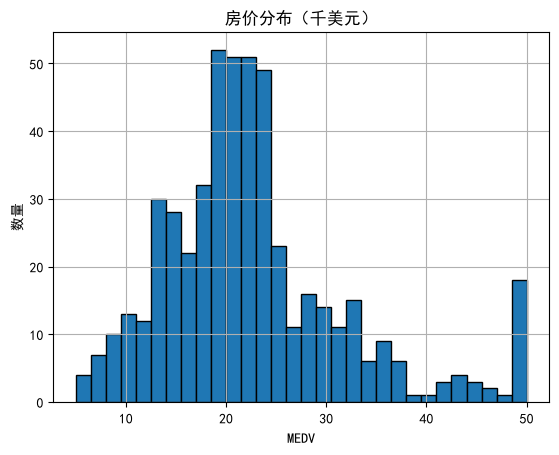

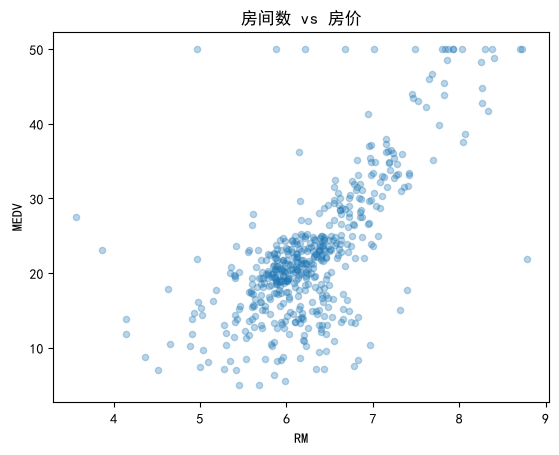

In [12]:
import matplotlib.pyplot as plt

# 房价分布
df["MEDV"].hist(bins=30, edgecolor="black")
plt.title("房价分布（千美元）")
plt.xlabel("MEDV")
plt.ylabel("数量")
plt.show()

# RM 和房价的散点
df.plot.scatter(x="RM", y="MEDV", alpha=0.3)
plt.title("房间数 vs 房价")
plt.show()

In [11]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]   # Windows 自带黑体
plt.rcParams["axes.unicode_minus"] = False      # 负号正常显示

In [13]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="MEDV")
y = df["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("训练集:", X_train.shape, "测试集:", X_test.shape)

训练集: (404, 13) 测试集: (101, 13)


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("RMSE:", mean_squared_error(y_test, pred) ** 0.5)
print("R²:", r2_score(y_test, pred))

RMSE: 4.402163231428005
R²: 0.6522201888666219


In [15]:
from sklearn.model_selection import cross_val_score
import numpy as np

# 5 折交叉验证：把训练集切成 5 份，轮流用 4 份练、1 份验
lr = LinearRegression()
cv_scores = cross_val_score(lr, X_train, y_train, cv=5,
                            scoring="neg_root_mean_squared_error")
print("线性回归 5 折 RMSE:", -cv_scores.mean(), "±", cv_scores.std())

线性回归 5 折 RMSE: 5.021265479405416 ± 0.6850142138431657


In [16]:
from lightgbm import LGBMRegressor

lgbm = LGBMRegressor(n_estimators=200, learning_rate=0.05, random_state=42)
lgbm.fit(X_train, y_train)

pred_lgbm = lgbm.predict(X_test)
print("LightGBM RMSE:", mean_squared_error(y_test, pred_lgbm) ** 0.5)
print("LightGBM R²:", r2_score(y_test, pred_lgbm))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000272 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1023
[LightGBM] [Info] Number of data points in the train set: 404, number of used features: 13
[LightGBM] [Info] Start training from score 22.869059
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

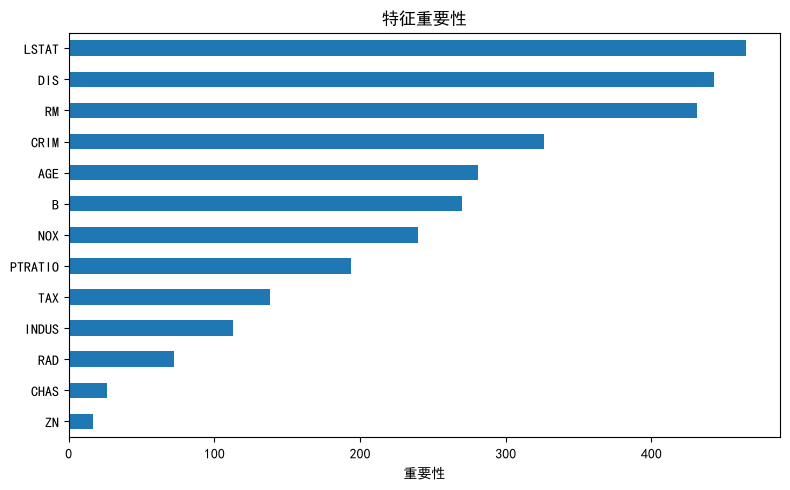

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

imp = pd.Series(lgbm.feature_importances_, index=X.columns)
imp.sort_values().plot.barh(figsize=(8, 5))
plt.title("特征重要性")
plt.xlabel("重要性")
plt.tight_layout()
plt.show()

In [18]:
import joblib
joblib.dump(lgbm, "D:/ml-project1/housing_model.pkl")
print("模型已保存")

模型已保存
